# GEMS — Phase 4: remote-sensing features, geological encoders, self-supervised learning

Code-authoring workflow: nothing here was executed when it was written. Every expensive section is behind a `RUN_*` switch that defaults to `False`; finished runs are reloaded from `outputs/phase4/experiments/` (and Phase-3 runs from `outputs/phase3/experiments/`), so sections can be run one at a time.

**Recommended order** (stop after each step and read the table it prints):
1. §0-2 (no training) → `feature_registry.csv`.
2. §3 `RUN_RS_FEATURES`, then `RUN_RS_REDUNDANCY` (CPU, once).
3. §5 `RUN_CNN_B_DISTANCE`, `RUN_CNN_A_DTI_DISCOVERY`, `RUN_CNN_REDUCED` (P0, GPU) — independent of §3.
4. §4 `RUN_RS_LGBM`, then `RUN_RS_DISCOVERY`, then `RUN_RS_DROPGROUP` (P0, CPU).
5. §6-7 `RUN_DUAL_ENCODER`, `RUN_CONTEXT`, `RUN_AUX_HEADS`, `RUN_P4_DISCOVERY` (P1, GPU; needs §3 for the RS terrain channels).
6. §8-9 SSL only if §6 is healthy (P2). §10 EO interfaces (optional). §11-12 complementarity, promotion, findings.

Scoring is the Phase-3 one: per-fold binary top-area masks, cross-fitted area budget, exact DTI. Geographic DTI and pseudo-discovery DTI are different tasks and are never compared with each other; pseudo-discovery is always reported for both `excl` and `retained_fp` policies.

In [4]:
# Cell 0 — Resolve GEMS project root and configure imports

import sys
from pathlib import Path

def find_project_root(start=None):
    """Find the directory containing the gems_bench package."""
    current = Path(start or Path.cwd()).resolve()

    for directory in [current, *current.parents]:
        if (directory / "gems_bench").is_dir():
            return directory

    # Also handle notebooks/ and similar working directories
    for base in [current, *current.parents]:
        for candidate in [base / "GEMS", base / "src"]:
            if (candidate / "gems_bench").is_dir():
                return candidate

    raise FileNotFoundError(
        f"Cannot locate gems_bench from {current}.\n"
        "Check that the notebook is inside your project "
        "or specify PROJECT_ROOT explicitly."
    )

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)

import gems_bench

print("gems_bench imported successfully")

Project root: C:\Users\myben\Downloads\GEMS
Python: c:\Users\myben\.conda\envs\GEMS\python.exe
gems_bench imported successfully


In [5]:
import json
import time
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from gems_bench import external_eo as eo
from gems_bench import geophysical_ssl as ssl
from gems_bench import phase4_eval as ev
from gems_bench import phase4_training as tr
from gems_bench import rs_features
from gems_bench.geo_eval import _hillshade
from gems_bench.p3 import discovery3, ensemble3, lineaments
from gems_bench.p3.context import write_experiment_manifest
from gems_bench.phase4_context import load_context4

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 60)

# ---- switches: safe defaults, nothing expensive runs until you flip one ----
RUN_RS_FEATURES = True            # build the RS feature bank once (CPU, ~20-40 min, cached)
RUN_RS_REDUNDANCY = True          # Spearman redundancy audit vs existing features (CPU, minutes)
RUN_RS_LGBM = True                # RS01-RS05 geographic CV (CPU, ~1-4 min each)
RUN_RS_DISCOVERY = True           # RS pseudo-discovery models (3 whole-map fits each)
RUN_RS_DROPGROUP = True           # drop-one-family ablation on the best RS feature set
RUN_CNN_B_DISTANCE = True         # DL00: CNN-B inputs + distance-aware loss (GPU ~15 min)
RUN_CNN_A_DTI_DISCOVERY = True    # DL01: CNN-A distance-aware pseudo-discovery (GPU, 3 whole-map models)
RUN_CNN_REDUCED = True            # DL02: terrain + magnetic + gravity + basement CNN (GPU ~15 min)
RUN_CNN_CONTROL_DISCOVERY = True  # pseudo-discovery for DL00 / DL02
RUN_DUAL_ENCODER = True           # P4_B_ctrl, P4_B_concat, P4_B_gated (+ P4_A_repro if enabled), GPU ~20 min each
RUN_CONTEXT = True                # P4_C_context
RUN_AUX_HEADS = True              # P4_D_aux
RUN_P4_DISCOVERY = True           # pseudo-discovery for architectures.discovery (+ SSL01_transductive)
RUN_SSL_PRETRAIN = True           # SSL01 masked-autoencoder pretraining (strict x3 + transductive)
RUN_SSL02 = True                  # SSL02 cross-modal (only if SSL01 fine-tuning shows a gain)
RUN_SSL_FINETUNE = True           # fine-tune the ssl.arch model from the SSL encoders
RUN_EXTERNAL_DEM = True           # EO01 AOI selection (+ 1 m features for local tiles in data/external/dem1m)
RUN_EO_FOUNDATION = True          # EO03 guard only (deferred)
RUN_PHASE4_ENSEMBLE = True        # nested ensemble of promoted candidates + discovery check
OVERWRITE = True
CNN_REQUIRE_CUDA = True

ctx = load_context4()
CFG, C4 = ctx.cfg, ctx.cfg4
RS_CFG = rs_features.load_rs_config(ctx.paths.root / 'configs' / 'phase4' / 'rs_features.yaml')
OUT = ctx.paths.out
MATCH_FRAC = float(C4['match_frac'])
FOLDS_REL = ctx.bench.rel(ctx.folds.directory)
EXP_ROWS, MAPS, DISC = [], {}, []


def save(df, name, desc='', headline=True):
    return ctx.save_table(df, name, desc, where=OUT if headline else None)


def show(fig, name, desc=''):
    if fig is not None:
        ctx.save_fig(fig, name, desc)
        plt.show()


def manifest_row(exp_id, section, kind, params, features, run_dir):
    EXP_ROWS.append({'exp_id': exp_id, 'section': section, 'kind': kind, 'params': params, 'features': features,
                     'folds': FOLDS_REL, 'seed': CFG.seed, 'artifacts': ctx.paths.rel(Path(run_dir))})
    write_experiment_manifest(ctx, EXP_ROWS)


def add_map(name, exp_id=None):
    if exp_id:
        C4.setdefault('reuse', {}).setdefault('oof', {})[name] = exp_id
    MAPS[name] = ctx.oof(name)


def has_exp(exp_id, file='oof.tif'):
    return (ctx.paths.experiments / exp_id / file).exists()


def run_features(exp_id):
    return json.loads((ctx.run_dir(exp_id) / 'config.json').read_text(encoding='utf-8'))['features']


def run_history(name):
    exp = C4['reuse']['oof'].get(name)
    p = ctx.run_dir(exp) / 'history.csv' if exp else None
    return pd.read_csv(p) if p is not None and p.exists() else None


def require_cuda():
    import torch
    print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
    if CNN_REQUIRE_CUDA and not torch.cuda.is_available():
        raise RuntimeError('CUDA torch required: pip install --force-reinstall torch --index-url https://download.pytorch.org/whl/cu128')
    if torch.cuda.is_available():
        free, total = torch.cuda.mem_get_info()
        print(f'{torch.cuda.get_device_name(0)}: free {free / 2**30:.1f} / {total / 2**30:.1f} GiB')


print('outputs ->', OUT, '| folds', FOLDS_REL, '| RS specs', len(ctx.rs_specs))

outputs -> C:\Users\myben\Downloads\GEMS\outputs\phase4 | folds outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026 | RS specs 67


## 1 · Project state and artifact reload

Reuses Phase-2 G1 / G3 and the Phase-3 runs named in `configs/phase4/experiments.yaml` (`reuse`). `G3_D2` = G3 under the LightGBM variant used by every RS run (`D2_conservative`): the controlled reference for RS03-RS05. Nothing is retrained here.

In [6]:
P3 = ctx.p3paths.out
P3_REG = pd.read_csv(P3 / 'experiment_registry.csv').drop_duplicates('exp_id', keep='last')
P3_CPD = pd.read_csv(P3 / 'tables' / 'cnn_pseudo_discovery.csv')
display(P3_REG[['exp_id', 'dti_crossfit_area', 'area_fold_min', 'best_iters']].round(4))
print('Phase-3 pseudo-discovery, cross-fitted area (excl and retained_fp are different hidden-test hypotheses):')
display(P3_CPD[P3_CPD.row == 'crossfit_area'].pivot_table(index='model', columns='policy', values='dti').round(4))
for name in ['G1', 'G3']:
    add_map(name)
for name in C4['reuse']['oof']:
    if ctx.has_oof(name):
        add_map(name)
DISC = [m for m in ['G1', 'G3', 'G3_D2', 'CNN_A_bcedice'] if ctx.has_discovery(m)]
print('reused maps:', list(MAPS), '| with pseudo-discovery predictions:', DISC)

,exp_id,dti_crossfit_area,area_fold_min,best_iters
0,p3_lgbm_D0_p2_replica_G3_s2026,0.1188,0.1039,"[17.0, 17.0, 9.0]"
1,p3_lgbm_D1_es_auc_G3_s2026,0.1239,0.1142,"[17.0, 80.0, 129.0]"
2,p3_lgbm_D2_conservative_G3_s2026,0.1307,0.1175,"[16.0, 93.0, 78.0]"
3,p3_lgbm_D3_conservative_lr_G3_s2026,0.1303,0.1165,"[36.0, 376.0, 255.0]"
4,p3_lgbm_D4_complex_lr_G3_s2026,0.1171,0.1122,"[15.0, 428.0, 693.0]"
5,p3_lgbm_D5_conservative_S2_G3_s2026,0.1152,0.1018,"[33.0, 43.0, 39.0]"
6,p3_lgbm_D6_cons_lr_S2_G3_s2026,0.1151,0.0954,"[125.0, 222.0, 289.0]"
7,p3_lgbm_F1_fixed100_C2_G3_s2026,0.1331,0.1168,"[100.0, 100.0, 100.0]"
8,p3_lgbm_F2_fixed400_C2_G3_s2026,0.1315,0.1153,"[400.0, 400.0, 400.0]"
9,p3_lgbm_F3_fixed400_C1_G3_s2026,0.1161,0.1101,"[400.0, 400.0, 400.0]"


Phase-3 pseudo-discovery, cross-fitted area (excl and retained_fp are different hidden-test hypotheses):


policy,excl,retained_fp
model,,
CNN_A_bcedice,0.1450,0.0756
G1,0.1001,0.0849
G3,0.0752,0.0585


reused maps: ['G1', 'G3', 'G3_D2', 'CNN_A_bcedice', 'CNN_A_dti', 'CNN_B_bcedice'] | with pseudo-discovery predictions: ['G1', 'G3', 'G3_D2', 'CNN_A_bcedice']


## 2 · Remote-sensing feature registry

Catalogue: `configs/phase4/rs_features.yaml` → `gems_bench/rs_features.py`. Groups `RS_T` (terrain / geomorphometry on **detrended** elevation), `RS_P` (magnetic / gravity / basement structure), `RS_X` (cross-modal, axial orientation statistics, agreement never forced). All label-free; support beyond the 13 km fold buffer means validation-area *inputs* are seen (as in Phase 2), never labels.

In [7]:
REG = ctx.store.full_registry()
REG['exceeds_buffer'] = REG.support_km > CFG.buffer_km
save(REG, 'feature_registry', 'Phase-2 + Phase-4 RS feature registry: spec, basis, support, cache path', headline=True)
RS_NAMES = ctx.store.rs_names
rs_tab = REG[REG.phase == 'phase4_rs']
display(rs_tab.groupby(['groups', 'family', 'basis']).size().rename('n_features').reset_index())
print('RS features whose input support exceeds the', CFG.buffer_km, 'km fold buffer (validation INPUTS only, never labels):')
print(rs_tab[rs_tab.exceeds_buffer].name.tolist())

,groups,family,basis,n_features
0,RS_P,analytic_signal,isostatic_residual_gravity,1
1,RS_P,analytic_signal,rtp_field,2
2,RS_P,gabor_bank,isostatic_residual_gravity,3
3,RS_P,gabor_bank,rtp_field,7
4,RS_P,hessian_ridge,rtp_field,1
5,RS_P,persistence,isostatic_residual_gravity,2
6,RS_P,persistence,rtp_field,2
7,RS_P,pf_coherence,isostatic_residual_gravity,1
8,RS_P,pf_coherence,rtp_field,1
9,RS_P,pyramid,isostatic_residual_gravity,1


RS features whose input support exceeds the 13.0 km fold buffer (validation INPUTS only, never labels):
['rs:xmod:edge_contrast_terrain@1km', 'rs:xmod:edge_contrast_magnetic@1km']


## 3 · Advanced feature engineering (`RUN_RS_FEATURES`, `RUN_RS_REDUNDANCY`)

Features are cached as `.npy` in `outputs/phase4/cache/features/` (registry `rs_feature_registry.csv`, timings `rs_feature_build_log.csv`). The redundancy audit flags RS features with |Spearman| ≥ 0.95 against any existing feature (e.g. analytic signal vs the provided `tmi_hg` / `tmi_vg` bands); flagged features are excluded from the RS groups used in §4.

In [8]:
if RUN_RS_FEATURES:
    t0 = time.perf_counter()
    ctx.store.build(RS_NAMES)
    print(f'RS bank built in {(time.perf_counter() - t0) / 60:.1f} min')
print('cached RS features:', sum(ctx.store.has(n) for n in RS_NAMES), '/', len(RS_NAMES))
RED_PATH = ctx.paths.tables / 'rs_redundancy_audit.csv'
if RUN_RS_REDUNDANCY:
    legacy = [n for n in ctx.store.specs if n not in set(RS_NAMES)]
    RED = rs_features.redundancy_audit(ctx.store, RS_NAMES, legacy, n=RS_CFG['redundancy']['sample_px'],
                                       threshold=RS_CFG['redundancy']['max_abs_spearman'])
    save(RED, 'rs_redundancy_audit', 'max |Spearman| of each RS feature vs existing (and earlier RS) features')
RED = pd.read_csv(RED_PATH) if RED_PATH.exists() else pd.DataFrame(columns=['name', 'redundant', 'max_abs_spearman'])
REDUNDANT = set(RED[RED.redundant.astype(bool)].name) if RS_CFG['redundancy']['drop_redundant'] else set()
print('redundant RS features excluded from the RS groups:', sorted(REDUNDANT))
display(RED.sort_values('max_abs_spearman', ascending=False).head(15))

  feature rs:terrain:tpi@0.3km                                    11.2s  robust-z
  feature rs:terrain:tpi@1km                                       3.8s  robust-z
  feature rs:terrain:tri@0.1km                                     3.8s  robust-z
  feature rs:terrain:tri@0.3km                                     4.4s  robust-z
  feature rs:terrain:range@1km                                     3.3s  robust-z
  feature rs:terrain:range@2km                                     3.4s  robust-z
  feature rs:terrain:curv_profile@0.5km                            8.5s  robust-z
  feature rs:terrain:curv_profile@1km                             12.8s  robust-z
  feature rs:terrain:curv_plan@0.5km                               1.4s  robust-z
  feature rs:terrain:curv_plan@1km                                 1.4s  robust-z
  feature rs:terrain:laplacian@0.5km                               6.0s  robust-z
  feature rs:terrain:hillshade_perp_s17.5@0.3km                   10.2s  robust-z
  feature rs:ter

,name,redundant,max_abs_spearman


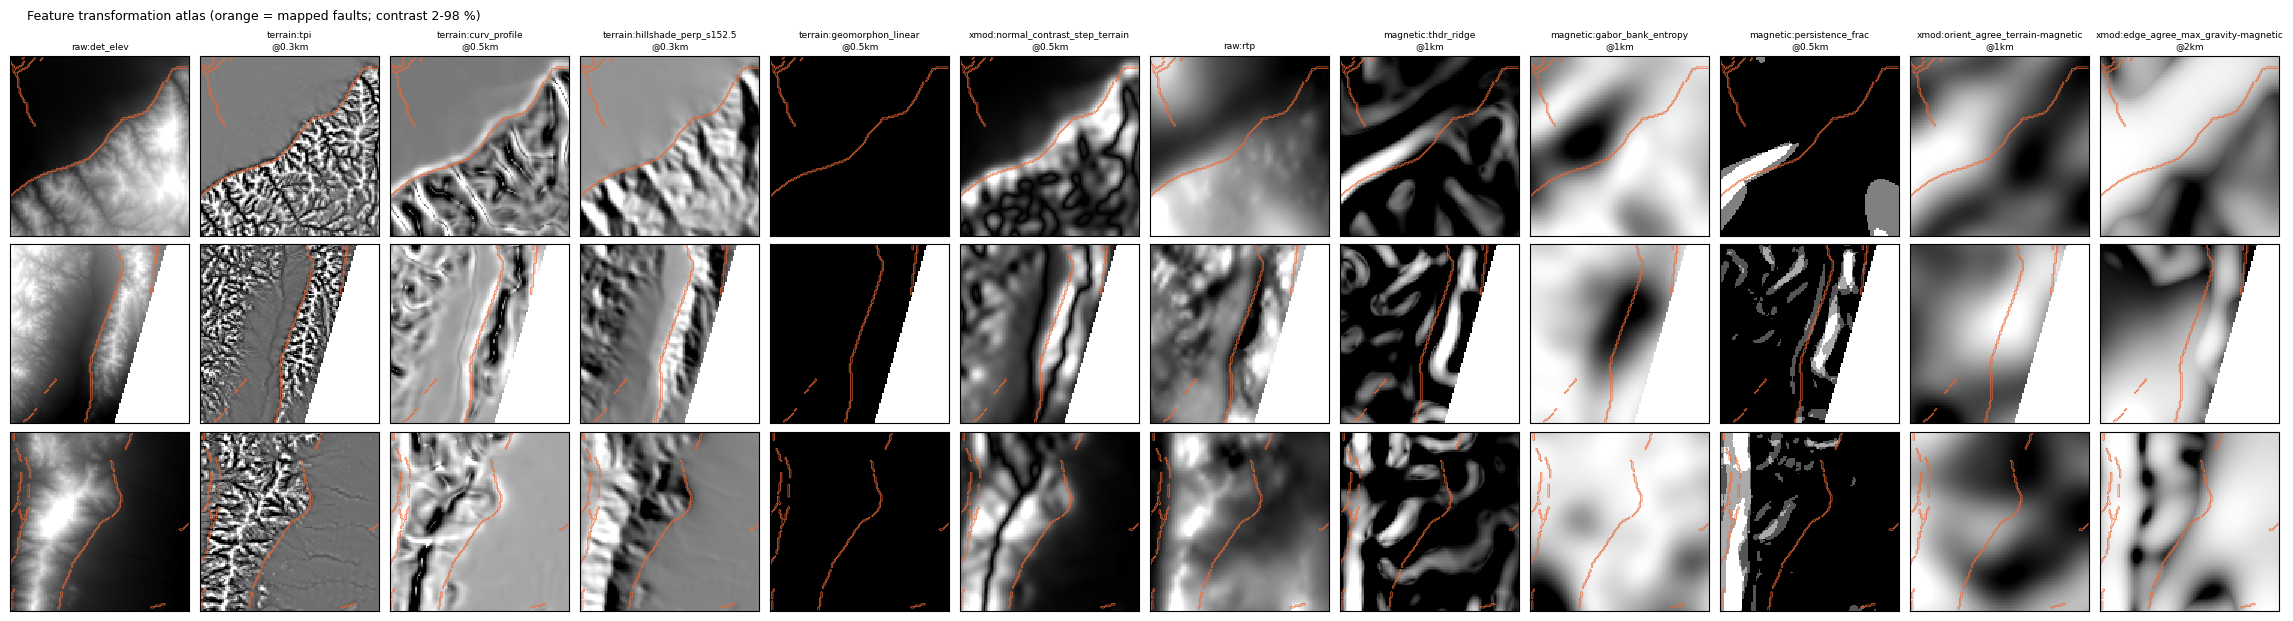

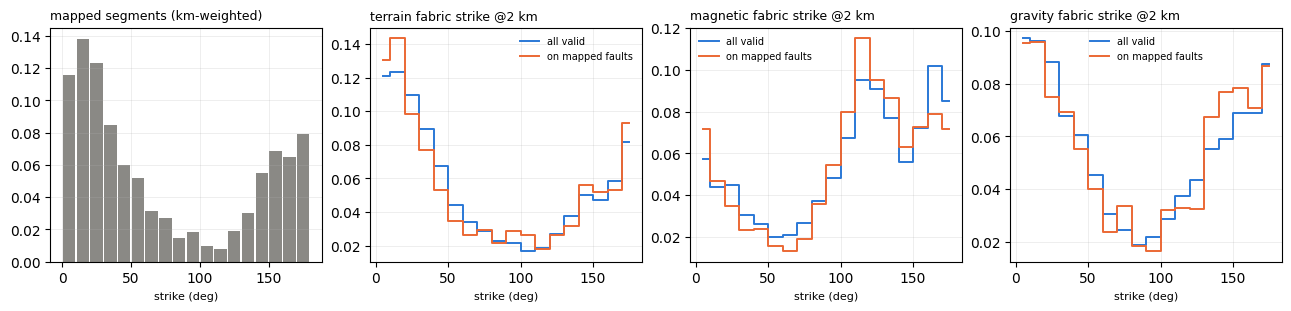

In [9]:
ATLAS = ['raw:det_elev', 'rs:terrain:tpi@0.3km', 'rs:terrain:curv_profile@0.5km', 'rs:terrain:hillshade_perp_s152.5@0.3km',
         'rs:terrain:geomorphon_linear@0.5km', 'rs:xmod:normal_contrast_step_terrain@0.5km', 'raw:rtp',
         'rs:magnetic:thdr_ridge@1km', 'rs:magnetic:gabor_bank_entropy@1km', 'rs:magnetic:persistence_frac@0.5km',
         'rs:xmod:orient_agree_terrain-magnetic@1km', 'rs:xmod:edge_agree_max_gravity-magnetic@2km']
if sum(ctx.store.has(n) for n in ATLAS) >= 8:
    H, W = ctx.data.shape
    lpt = ev.label_pixel_table(ctx)
    longest = ctx.seg_tab.sort_values('length_km', ascending=False).seg_id
    cent = lpt.groupby('seg_id')[['r', 'c']].median().reindex(longest).dropna()
    WIN = [(int(np.clip(r - 60, 0, H - 120)), int(np.clip(c - 60, 0, W - 120)), 120)
           for r, c in cent.to_numpy()[[i for i in (0, 15, 40) if i < len(cent)]]]
    show(rs_features.feature_atlas(ctx.store, ATLAS, WIN, ctx.data.labels), 'feature_transformation_atlas',
         'terrain (top) and subsurface / cross-modal (right) evidence on three long mapped faults, 12 km windows')
    show(rs_features.orientation_rose(ctx.store, ctx.seg_tab, ctx.data.labels), 'directional_structure_comparison',
         'coherence-weighted fabric strike per modality (all valid vs on faults) and mapped segment strikes')

## 4 · LightGBM feature ablations (`RUN_RS_LGBM`, `RUN_RS_DISCOVERY`, `RUN_RS_DROPGROUP`)

RS01 G1 · RS02 G1 + RS_T · RS03 G3 + RS_P · RS04 G3 + RS_X · RS05c G3 without seismicity/strain (control) · RS05 RS05c + all RS. Same folds, sampler, seed, variant (`D2_conservative`) as the reused reference `G3_D2`. Drop-group ablation removes one RS family at a time from the best RS set: a negative delta means the family adds predictive value (gain share alone is never used as evidence).

In [10]:
LG = C4['lgbm']
VARIANT = LG['variant']
RS_FEATS = {k: tr.rs_experiment_features(ctx, d, REDUNDANT) for k, d in LG['experiments'].items()}
NOT_READY = [k for k, d in LG['experiments'].items() if d.get('add_groups') and not any(n.startswith('rs:') for n in RS_FEATS[k])]
print({k: len(v) for k, v in RS_FEATS.items()}, '| not ready (build RS features first):', NOT_READY)
if RUN_RS_LGBM:
    for key, names in RS_FEATS.items():
        if key in NOT_READY:
            continue
        run = tr.run_rs_cv(ctx, key, names, VARIANT, overwrite=OVERWRITE)
        manifest_row(run.exp_id, '4', 'lgbm_cv', {'variant': VARIANT, **LG['experiments'][key]}, names, run.dir)
for key in LG['experiments']:
    if has_exp(tr.lgbm_exp_id(ctx, key)):
        add_map(key, tr.lgbm_exp_id(ctx, key))
if RUN_RS_DISCOVERY:
    for key in LG['discovery']:
        if key in MAPS:
            names = run_features(tr.lgbm_exp_id(ctx, key))
            rounds = tr.run_rs_discovery(ctx, key, names, VARIANT, overwrite=OVERWRITE)
            manifest_row(f'disc_{key}', '4', 'lgbm_discovery', {'variant': VARIANT, 'rounds': rounds}, names,
                         ctx.paths.experiments)
DISC += [k for k in LG['experiments'] if k not in DISC and ctx.has_discovery(k)]
print('RS maps:', [k for k in LG['experiments'] if k in MAPS], '| with discovery:', [k for k in LG['experiments'] if k in DISC])

{'RS01_G1': 19, 'RS02_G1_terrain': 42, 'RS03_G3_potential': 80, 'RS04_G3_crossmodal': 68, 'RS05c_G3_noSS': 47, 'RS05_G3_noSS_RS': 114} | not ready (build RS features first): []
[p4_RS01_G1_s2026] fold 0: it=411 raw DTI=0.0627 AUC=0.715
[p4_RS01_G1_s2026] fold 1: it=121 raw DTI=0.0772 AUC=0.645
[p4_RS01_G1_s2026] fold 2: it=2 raw DTI=0.0557 AUC=0.675


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS01_G1_s2026] cross-fitted area DTI=0.1301  raw=0.0644
[p4_RS02_G1_terrain_s2026] fold 0: it=2 raw DTI=0.0479 AUC=0.708
[p4_RS02_G1_terrain_s2026] fold 1: it=92 raw DTI=0.0771 AUC=0.646
[p4_RS02_G1_terrain_s2026] fold 2: it=2 raw DTI=0.0559 AUC=0.721


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS02_G1_terrain_s2026] cross-fitted area DTI=0.1414  raw=0.0586
[p4_RS03_G3_potential_s2026] fold 0: it=10 raw DTI=0.0505 AUC=0.735
[p4_RS03_G3_potential_s2026] fold 1: it=28 raw DTI=0.0726 AUC=0.655
[p4_RS03_G3_potential_s2026] fold 2: it=10 raw DTI=0.0575 AUC=0.639


...

[p4_RS04_G3_crossmodal_s2026] cross-fitted area DTI=0.1359  raw=0.0647
[p4_RS05c_G3_noSS_s2026] fold 0: it=3 raw DTI=0.0481 AUC=0.716
[p4_RS05c_G3_noSS_s2026] fold 1: it=106 raw DTI=0.0785 AUC=0.665
[p4_RS05c_G3_noSS_s2026] fold 2: it=40 raw DTI=0.0634 AUC=0.672


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS05c_G3_noSS_s2026] cross-fitted area DTI=0.1181  raw=0.0617
[p4_RS05_G3_noSS_RS_s2026] fold 0: it=3 raw DTI=0.0481 AUC=0.704
[p4_RS05_G3_noSS_RS_s2026] fold 1: it=116 raw DTI=0.0796 AUC=0.662
[p4_RS05_G3_noSS_RS_s2026] fold 2: it=30 raw DTI=0.0645 AUC=0.707


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS05_G3_noSS_RS_s2026] cross-fitted area DTI=0.1429  raw=0.0621
RS maps: ['RS01_G1', 'RS02_G1_terrain', 'RS03_G3_potential', 'RS04_G3_crossmodal', 'RS05c_G3_noSS', 'RS05_G3_noSS_RS'] | with discovery: ['RS01_G1', 'RS02_G1_terrain', 'RS03_G3_potential', 'RS04_G3_crossmodal', 'RS05c_G3_noSS', 'RS05_G3_noSS_RS']


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

scorecard: 9 maps, 9 discovery models in 339s


,model,geo_dti,geo_fold_min,disc_dti_excl,disc_dti_retained_fp,short_recall_w,recall_w_len_<1
0,G1,0.1327,0.1165,0.1001,0.0849,0.1376,0.1373
1,G3,0.1154,0.0993,0.0752,0.0585,0.1290,0.1466
2,G3_D2,0.1307,0.1175,0.0791,0.0638,0.1502,0.1543
3,RS01_G1,0.1301,0.0945,0.1068,0.0897,0.1483,0.1475
4,RS02_G1_terrain,0.1414,0.1257,0.0976,0.0838,0.1806,0.1880
5,RS03_G3_potential,0.1253,0.1054,0.0588,0.0496,0.1399,0.1528
6,RS04_G3_crossmodal,0.1359,0.1244,0.0759,0.0622,0.1438,0.1547
7,RS05c_G3_noSS,0.1181,0.1124,0.0895,0.0789,0.1453,0.1582
8,RS05_G3_noSS_RS,0.1429,0.1315,0.1186,0.0945,0.1626,0.1548


,candidate,control,set,folds_beating,fold_deltas,geo_dti_cand,geo_dti_ctrl,delta_geo_dti,geo_fold_min_cand,geo_fold_min_ctrl,delta_geo_fold_min,geo_recall300_at_match_cand,geo_recall300_at_match_ctrl,delta_geo_recall300_at_match,short_recall_w_cand,short_recall_w_ctrl,delta_short_recall_w,recall_w_len_<1_cand,recall_w_len_<1_ctrl,delta_recall_w_len_<1,recall_w_len_1-2_cand,recall_w_len_1-2_ctrl,delta_recall_w_len_1-2,recall_w_len_5-10_cand,recall_w_len_5-10_ctrl,delta_recall_w_len_5-10,recall_w_len_>10_cand,recall_w_len_>10_ctrl,delta_recall_w_len_>10,recall_w_curved_cand,recall_w_curved_ctrl,delta_recall_w_curved,recall_w_endpoint_cand,recall_w_endpoint_ctrl,delta_recall_w_endpoint,recall_w_intersection_cand,recall_w_intersection_ctrl,delta_recall_w_intersection,disc_dti_excl_cand,disc_dti_excl_ctrl,delta_disc_dti_excl,disc_dti_retained_fp_cand,disc_dti_retained_fp_ctrl,delta_disc_dti_retained_fp,geo_far_share_at_match_cand,geo_far_share_at_match_ctrl,delta_geo_far_share_at_match
0,RS02_G1_terrain,RS01_G1,rs_lgbm,1,"[-0.0072, -0.0109, 0.0506]",0.1414,0.1301,0.0113,0.1257,0.0945,0.0312,0.3603,0.2855,0.0748,0.1806,0.1483,0.0323,0.1880,0.1475,0.0405,0.1769,0.1482,0.0287,0.3573,0.2726,0.0847,0.5778,0.4814,0.0964,0.3110,0.2551,0.0559,0.2349,0.1789,0.0559,0.2447,0.2178,0.0269,0.0976,0.1068,-0.0091,0.0838,0.0897,-0.0059,0.5624,0.5347,0.0278
1,RS03_G3_potential,G3_D2,rs_lgbm,1,"[-0.008, 0.0058, -0.0155]",0.1253,0.1307,-0.0054,0.1054,0.1175,-0.0121,0.2332,0.2652,-0.0320,0.1399,0.1502,-0.0102,0.1528,0.1543,-0.0014,0.1324,0.1479,-0.0155,0.2366,0.2610,-0.0244,0.3820,0.4432,-0.0612,0.2611,0.2866,-0.0255,0.1566,0.1744,-0.0178,0.1998,0.2179,-0.0181,0.0588,0.0791,-0.0203,0.0496,0.0638,-0.0141,0.4994,0.4814,0.0180
2,RS04_G3_crossmodal,G3_D2,rs_lgbm,3,"[0.0001, 0.0069, 0.0068]",0.1359,0.1307,0.0052,0.1244,0.1175,0.0069,0.2681,0.2652,0.0029,0.1438,0.1502,-0.0064,0.1547,0.1543,0.0005,0.1374,0.1479,-0.0105,0.2740,0.2610,0.0130,0.4455,0.4432,0.0023,0.2793,0.2866,-0.0073,0.1772,0.1744,0.0028,0.2109,0.2179,-0.0071,0.0759,0.0791,-0.0032,0.0622,0.0638,-0.0016,0.4924,0.4814,0.0110
3,RS05c_G3_noSS,G3_D2,rs_lgbm,1,"[-0.0348, 0.004, -0.0086]",0.1181,0.1307,-0.0126,0.1124,0.1175,-0.0051,0.2557,0.2652,-0.0095,0.1453,0.1502,-0.0049,0.1582,0.1543,0.0040,0.1385,0.1479,-0.0094,0.2776,0.2610,0.0166,0.4128,0.4432,-0.0304,0.2816,0.2866,-0.0050,0.1705,0.1744,-0.0039,0.2115,0.2179,-0.0064,0.0895,0.0791,0.0104,0.0789,0.0638,0.0151,0.5323,0.4814,0.0509
4,RS05_G3_noSS_RS,RS05c_G3_noSS,rs_lgbm,3,"[0.0259, 0.01, 0.0387]",0.1429,0.1181,0.0248,0.1315,0.1124,0.0192,0.2936,0.2557,0.0380,0.1626,0.1453,0.0174,0.1548,0.1582,-0.0034,0.1675,0.1385,0.0290,0.3047,0.2776,0.0271,0.4895,0.4128,0.0767,0.2446,0.2816,-0.0370,0.1940,0.1705,0.0235,0.1944,0.2115,-0.0172,0.1186,0.0895,0.0291,0.0945,0.0789,0.0156,0.5230,0.5323,-0.0093


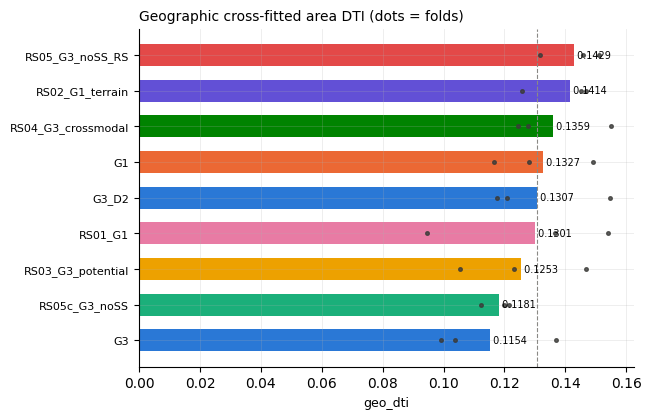

In [11]:
ABL = pd.DataFrame()
RS_KEYS = [k for k in ['G1', 'G3', 'G3_D2', *LG['experiments']] if k in MAPS]
if any(k in MAPS for k in LG['experiments']):
    SC_RS = ev.scorecard(ctx, {k: MAPS[k] for k in RS_KEYS}, [k for k in DISC if k in RS_KEYS], MATCH_FRAC)
    save(SC_RS['score'], 'rs_lgbm_scorecard', 'RS LightGBM scorecard: geographic, pseudo-discovery, thin structures')
    ABL = ev.comparison_rows(SC_RS['score'], LG['comparisons'], 'rs_lgbm')
    GIMP = pd.concat([rs_features.group_importance(pd.read_csv(ctx.run_dir(tr.lgbm_exp_id(ctx, k)) / 'importance.csv'), ctx.store)
                      .assign(experiment=k) for k in LG['experiments'] if k in MAPS], ignore_index=True)
    save(GIMP, 'rs_group_importance', 'gain share per feature family and fold (descriptive only)')
    cols = ['model', 'geo_dti', 'geo_fold_min', 'disc_dti_excl', 'disc_dti_retained_fp', 'short_recall_w', 'recall_w_len_<1']
    display(SC_RS['score'][[c for c in cols if c in SC_RS['score']]].round(4))
    display(ABL.round(4))
    show(ev.fig_metric_bars(SC_RS['score'], 'geo_dti', 'Geographic cross-fitted area DTI (dots = folds)',
                            [c for c in SC_RS['score'] if c.startswith('dti_fold')], 'G3_D2'), 'rs_geo_dti_comparison')

In [12]:
if RUN_RS_DROPGROUP and any(k in MAPS for k in LG['experiments']):
    cand = [k for k in LG['experiments'] if k in MAPS and LG['experiments'][k].get('add_groups')]
    base = LG['drop_group_base']
    if base == 'auto':
        base = SC_RS['score'].set_index('model').loc[cand].geo_dti.idxmax()
    DG = tr.drop_group_runs(ctx, base, run_features(tr.lgbm_exp_id(ctx, base)), VARIANT, overwrite=OVERWRITE)
    for key, (fam, run) in DG.items():
        add_map(key, run.exp_id)
        manifest_row(run.exp_id, '4', 'lgbm_drop_group', {'base': base, 'dropped_family': fam}, run.config['features'], run.dir)
    sc = ev.scorecard(ctx, {k: MAPS[k] for k in [base, *DG]}, [], MATCH_FRAC)['score']
    dg = ev.comparison_rows(sc, [(k, base) for k in DG], 'drop_group')
    dg.insert(2, 'dropped_family', [DG[k][0] for k in dg.candidate])
    display(dg[[c for c in ['candidate', 'dropped_family', 'delta_geo_dti', 'folds_beating', 'delta_short_recall_w'] if c in dg]].round(4))
    ABL = pd.concat([ABL, dg], ignore_index=True)
if len(ABL):
    save(ABL, 'rs_feature_ablation', 'RS ablations: candidate - control deltas (negative drop-group delta = the family helps)',
         headline=True)

[p4_RS05_G3_noSS_RS_drop_RS_T-tpi_s2026] fold 0: it=2 raw DTI=0.0478 AUC=0.686
[p4_RS05_G3_noSS_RS_drop_RS_T-tpi_s2026] fold 1: it=50 raw DTI=0.0760 AUC=0.662
[p4_RS05_G3_noSS_RS_drop_RS_T-tpi_s2026] fold 2: it=2 raw DTI=0.0558 AUC=0.675


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS05_G3_noSS_RS_drop_RS_T-tpi_s2026] cross-fitted area DTI=0.1240  raw=0.0583
[p4_RS05_G3_noSS_RS_drop_RS_T-tri_s2026] fold 0: it=2 raw DTI=0.0478 AUC=0.685
[p4_RS05_G3_noSS_RS_drop_RS_T-tri_s2026] fold 1: it=157 raw DTI=0.0799 AUC=0.660
[p4_RS05_G3_noSS_RS_drop_RS_T-tri_s2026] fold 2: it=69 raw DTI=0.0695 AUC=0.704


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS05_G3_noSS_RS_drop_RS_T-tri_s2026] cross-fitted area DTI=0.1398  raw=0.0633
[p4_RS05_G3_noSS_RS_drop_RS_T-local_relief_s2026] fold 0: it=2 raw DTI=0.0478 AUC=0.691
[p4_RS05_G3_noSS_RS_drop_RS_T-local_relief_s2026] fold 1: it=93 raw DTI=0.0785 AUC=0.663
[p4_RS05_G3_noSS_RS_drop_RS_T-local_relief_s2026] fold 2: it=79 raw DTI=0.0701 AUC=0.702


...

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_RS05_G3_noSS_RS_drop_RS_X-xmod_persistence_s2026] cross-fitted area DTI=0.1442  raw=0.0614


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

scorecard: 25 maps, 0 discovery models in 150s


,candidate,dropped_family,delta_geo_dti,folds_beating,delta_short_recall_w
0,RS05_G3_noSS_RS_drop_RS_T-tpi,RS_T:tpi,-0.0189,0,-0.0031
1,RS05_G3_noSS_RS_drop_RS_T-tri,RS_T:tri,-0.0030,0,0.0140
2,RS05_G3_noSS_RS_drop_RS_T-local_relief,RS_T:local_relief,-0.0063,0,0.0098
3,RS05_G3_noSS_RS_drop_RS_T-curvature_pp,RS_T:curvature_pp,-0.0236,0,-0.0116
4,RS05_G3_noSS_RS_drop_RS_T-laplacian,RS_T:laplacian,0.0046,1,0.0024
5,RS05_G3_noSS_RS_drop_RS_T-hillshade,RS_T:hillshade,-0.0180,1,-0.0032
6,RS05_G3_noSS_RS_drop_RS_T-slope_break,RS_T:slope_break,-0.0059,1,0.0027
7,RS05_G3_noSS_RS_drop_RS_T-geomorphon,RS_T:geomorphon,-0.0123,0,0.0030
8,RS05_G3_noSS_RS_drop_RS_T-terrain_coherence,RS_T:terrain_coherence,-0.0066,1,-0.0029
9,RS05_G3_noSS_RS_drop_RS_T-persistence,RS_T:persistence,-0.0065,1,-0.0001


## 5 · Missing Phase-3 CNN comparisons (P0: `RUN_CNN_B_DISTANCE`, `RUN_CNN_A_DTI_DISCOVERY`, `RUN_CNN_REDUCED`)

* **DL00** CNN-B inputs (raw + 10 engineered), only the loss changes to the distance-aware DTI surrogate. Spec re-loaded from the Phase-3 `config.json`; same folds, epochs cap, sampler, patience, inference.
* **DL01** CNN-A distance-aware pseudo-discovery with the Phase-3 rule (epochs = median best epoch of its CV run) and the identical scoring as CNN-A BCE+Dice: same withheld systems, ring, policies, budgets. Read `excl` and `retained_fp` separately (Phase 3: CNN-A BCE+Dice led under `excl` but trailed G1 under `retained_fp`).
* **DL02** terrain + magnetic + gravity + basement raw bands (no seismicity, strain, conductivity), distance-aware loss; control = CNN_A_dti. DL02b (drop only seismicity/strain) is disabled in the config until DL02 differs from CNN_A_dti.

In [13]:
CC = C4['cnn_controls']
if RUN_CNN_B_DISTANCE or RUN_CNN_REDUCED or RUN_CNN_A_DTI_DISCOVERY or RUN_CNN_CONTROL_DISCOVERY:
    require_cuda()
if RUN_CNN_B_DISTANCE:
    d = CC['DL00_CNN_B_dti']
    spec = tr.phase3_cnn_spec(ctx, d['from_phase3'], name='DL00_CNN_B_dti', **d['override'])
    run = tr.run_cnn_control(ctx, 'DL00_CNN_B_dti', spec, overwrite=OVERWRITE)
    manifest_row(run.exp_id, '5', 'cnn_control', {'from': d['from_phase3'], **d['override']}, spec.channels, run.dir)
if RUN_CNN_REDUCED:
    for key in ('DL02_CNN_TMGB_dti', 'DL02b_CNN_noSS_dti'):
        d = CC[key]
        if not d.get('enabled', True):
            continue
        base = tr.phase3_cnn_spec(ctx, d['from_phase3'])
        chans = tr.modality_filter(ctx, base.channels, keep=d.get('keep_modalities'), drop=d.get('drop_modalities'))
        spec = replace(base, name=key, channels=chans)
        run = tr.run_cnn_control(ctx, key, spec, overwrite=OVERWRITE)
        manifest_row(run.exp_id, '5', 'cnn_control', {'from': d['from_phase3'], 'n_channels': len(chans)}, chans, run.dir)
for key in ('DL00_CNN_B_dti', 'DL02_CNN_TMGB_dti', 'DL02b_CNN_noSS_dti'):
    if has_exp(tr.cnn_exp_id(ctx, key, 256)):
        add_map(key, tr.cnn_exp_id(ctx, key, 256))
if RUN_CNN_A_DTI_DISCOVERY:
    spec = tr.phase3_cnn_spec(ctx, 'CNN_A_dti')
    ep = tr.run_cnn_control_discovery(ctx, 'CNN_A_dti', spec, C4['reuse']['oof']['CNN_A_dti'], overwrite=OVERWRITE)
    manifest_row('disc_CNN_A_dti', '5', 'cnn_discovery', {'epochs': ep, 'rule': 'median best epoch of the p3 CV run'},
                 spec.channels, ctx.paths.experiments)
if RUN_CNN_CONTROL_DISCOVERY:
    for key in CC['discovery']:
        if key in MAPS:
            cfg = json.loads((ctx.run_dir(C4['reuse']['oof'][key]) / 'config.json').read_text(encoding='utf-8'))
            spec = tr.spec_from_config(cfg)
            ep = tr.run_cnn_control_discovery(ctx, key, spec, C4['reuse']['oof'][key], overwrite=OVERWRITE)
            manifest_row(f'disc_{key}', '5', 'cnn_discovery', {'epochs': ep}, spec.channels, ctx.paths.experiments)
DISC += [k for k in ['CNN_A_dti', *CC['discovery']] if k not in DISC and ctx.has_discovery(k)]
print('CNN control maps:', [k for k in MAPS if k.startswith('DL')], '| discovery:', DISC)

torch 2.14.1+cu126 | cuda True
NVIDIA GeForce RTX 3070 Laptop GPU: free 6.9 / 8.0 GiB
[p4_DL00_CNN_B_dti_p256_s2026] device=cuda | stack on GPU: True | amp=torch.bfloat16
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   1 loss 0.9491 inner 0.1374  (36s train, 14s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   2 loss 0.8559 inner 0.1352  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   3 loss 0.7624 inner 0.1164  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   4 loss 0.6244 inner 0.1326  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   5 loss 0.4406 inner 0.1437  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   6 loss 0.2781 inner 0.1575  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   7 loss 0.1968 inner 0.1627  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   8 loss 0.1625 inner 0.1600  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep   9 loss 0.1330 inner 0.1841  (16s train, 0s eval)
[p4_DL00_CNN_B_dti_p256_s2026 f0] ep

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_DL00_CNN_B_dti_p256_s2026] cross-fitted area DTI=0.1496  raw=0.0855
[p4_DL02_CNN_TMGB_dti_p256_s2026] device=cuda | stack on GPU: True | amp=torch.bfloat16
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   1 loss 0.9951 inner 0.1489  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   2 loss 0.9430 inner 0.1585  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   3 loss 0.8835 inner 0.1514  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   4 loss 0.8085 inner 0.1360  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   5 loss 0.6694 inner 0.1502  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   6 loss 0.4327 inner 0.1507  (17s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   7 loss 0.2648 inner 0.1570  (17s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f0] ep   8 loss 0.1730 inner 0.1506  (17s train, 0s eval)
[p4_DL02_CNN_TMGB_dti_p256_s2026 f1] ep   1 loss 0.9867 inner 0.1187  (16s train, 0s eval)
[p4_DL02_CNN_TMGB_dti

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_DL02_CNN_TMGB_dti_p256_s2026] cross-fitted area DTI=0.1215  raw=0.0613
[disc0_CNN_A_dti] ep   1 loss 0.9663 inner nan  (16s train, 0s eval)
[disc0_CNN_A_dti] ep   2 loss 0.8741 inner nan  (16s train, 0s eval)
[disc0_CNN_A_dti] ep   3 loss 0.7128 inner nan  (17s train, 0s eval)
[disc0_CNN_A_dti] ep   4 loss 0.6347 inner nan  (19s train, 0s eval)
[disc0_CNN_A_dti] ep   5 loss 0.5920 inner nan  (18s train, 0s eval)
[disc0_CNN_A_dti] ep   6 loss 0.5425 inner nan  (18s train, 0s eval)
[disc0_CNN_A_dti] ep   7 loss 0.5062 inner nan  (19s train, 0s eval)
[disc0_CNN_A_dti] ep   8 loss 0.4639 inner nan  (19s train, 0s eval)
[disc0_CNN_A_dti] ep   9 loss 0.4344 inner nan  (19s train, 0s eval)
[disc0_CNN_A_dti] ep  10 loss 0.4145 inner nan  (19s train, 0s eval)
[disc1_CNN_A_dti] ep   1 loss 0.9618 inner nan  (17s train, 0s eval)
[disc1_CNN_A_dti] ep   2 loss 0.8663 inner nan  (20s train, 0s eval)
[disc1_CNN_A_dti] ep   3 loss 0.7156 inner nan  (23s train, 0s eval)
[disc1_CNN_A_dti] ep   4 los

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

DL01 cross-fitted pseudo-discovery DTI (compare within one column only):


,model,disc_dti_excl,disc_fold_min_excl,disc_frac_excl,disc_recall300_at_match_excl,disc_dti_retained_fp,disc_fold_min_retained_fp,disc_frac_retained_fp,disc_recall300_at_match_retained_fp
0,CNN_A_dti,0.1788,0.1187,0.03,0.3932,0.0918,0.0630,0.03,0.3932
1,CNN_A_bcedice,0.1450,0.1004,0.03,0.2779,0.0756,0.0430,0.03,0.2779
2,G1,0.1001,0.0758,0.05,0.3332,0.0849,0.0553,0.05,0.3332
3,G3,0.0752,0.0483,0.03,0.2037,0.0585,0.0376,0.02,0.2037


C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

scorecard: 7 maps, 6 discovery models in 104s


,candidate,control,set,folds_beating,fold_deltas,geo_dti_cand,geo_dti_ctrl,delta_geo_dti,geo_fold_min_cand,geo_fold_min_ctrl,delta_geo_fold_min,geo_recall300_at_match_cand,geo_recall300_at_match_ctrl,delta_geo_recall300_at_match,short_recall_w_cand,short_recall_w_ctrl,delta_short_recall_w,recall_w_len_<1_cand,recall_w_len_<1_ctrl,delta_recall_w_len_<1,recall_w_len_1-2_cand,recall_w_len_1-2_ctrl,delta_recall_w_len_1-2,recall_w_len_5-10_cand,recall_w_len_5-10_ctrl,delta_recall_w_len_5-10,recall_w_len_>10_cand,recall_w_len_>10_ctrl,delta_recall_w_len_>10,recall_w_curved_cand,recall_w_curved_ctrl,delta_recall_w_curved,recall_w_endpoint_cand,recall_w_endpoint_ctrl,delta_recall_w_endpoint,recall_w_intersection_cand,recall_w_intersection_ctrl,delta_recall_w_intersection,disc_dti_excl_cand,disc_dti_excl_ctrl,delta_disc_dti_excl,disc_dti_retained_fp_cand,disc_dti_retained_fp_ctrl,delta_disc_dti_retained_fp,geo_far_share_at_match_cand,geo_far_share_at_match_ctrl,delta_geo_far_share_at_match
0,DL00_CNN_B_dti,CNN_B_bcedice,cnn_controls,3,"[0.0569, 0.0189, 0.0383]",0.1496,0.1109,0.0387,0.1354,0.1067,0.0287,0.3941,0.2465,0.1476,0.1899,0.1334,0.0566,0.2028,0.1468,0.0561,0.1823,0.1256,0.0567,0.2931,0.1908,0.1023,0.4073,0.3768,0.0305,0.2811,0.1952,0.0859,0.2113,0.1611,0.0501,0.2441,0.1464,0.0977,0.1675,NaN,NaN,0.0807,NaN,NaN,0.6153,0.6050,0.0103
1,DL00_CNN_B_dti,CNN_A_dti,cnn_controls,2,"[0.0259, -0.0006, 0.0341]",0.1496,0.1302,0.0195,0.1354,0.1150,0.0204,0.3941,0.3509,0.0432,0.1899,0.1586,0.0314,0.2028,0.1636,0.0392,0.1823,0.1560,0.0262,0.2931,0.2682,0.0249,0.4073,0.4095,-0.0022,0.2811,0.2529,0.0283,0.2113,0.1837,0.0276,0.2441,0.2036,0.0405,0.1675,0.1788,-0.0113,0.0807,0.0918,-0.0111,0.6153,0.6415,-0.0262
2,CNN_A_dti,CNN_A_bcedice,cnn_controls,3,"[0.0304, 0.0222, 0.0077]",0.1302,0.1092,0.0209,0.1150,0.1072,0.0078,0.3509,0.2480,0.1029,0.1586,0.1249,0.0336,0.1636,0.1282,0.0354,0.1560,0.1230,0.0330,0.2682,0.2211,0.0471,0.4095,0.3997,0.0098,0.2529,0.1981,0.0548,0.1837,0.1545,0.0292,0.2036,0.1464,0.0572,0.1788,0.1450,0.0338,0.0918,0.0756,0.0162,0.6415,0.5998,0.0417
3,DL02_CNN_TMGB_dti,CNN_A_dti,cnn_controls,1,"[-0.0221, -0.0215, 0.0181]",0.1215,0.1302,-0.0086,0.1145,0.1150,-0.0005,0.2965,0.3509,-0.0544,0.1490,0.1586,-0.0095,0.1521,0.1636,-0.0115,0.1473,0.1560,-0.0087,0.2479,0.2682,-0.0203,0.3957,0.4095,-0.0138,0.2135,0.2529,-0.0393,0.1793,0.1837,-0.0043,0.1758,0.2036,-0.0278,0.1709,0.1788,-0.0079,0.0998,0.0918,0.0080,0.5947,0.6415,-0.0468


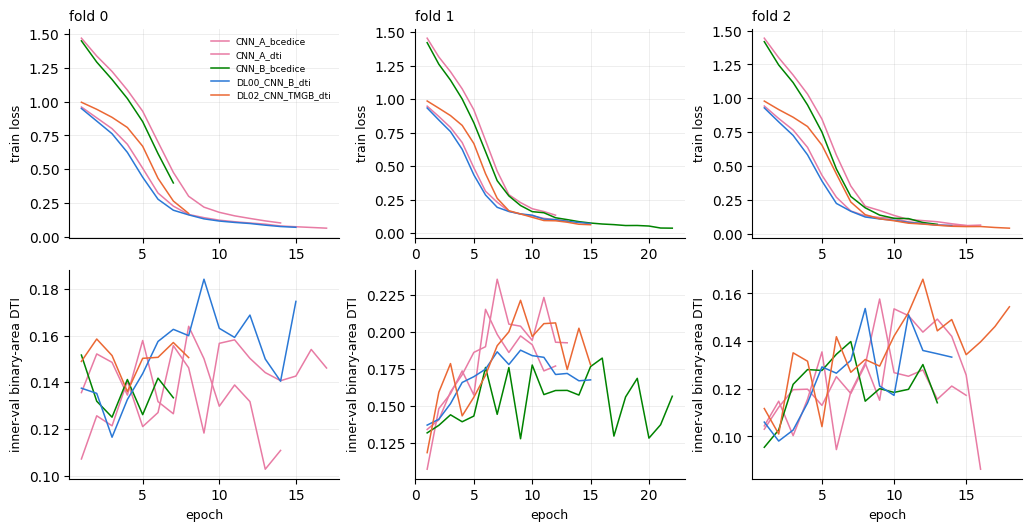

In [14]:
DL01 = [m for m in ['CNN_A_dti', 'CNN_A_bcedice', 'G1', 'G3'] if ctx.has_discovery(m)]
if 'CNN_A_dti' in DL01:
    D01, D01_SUM, _ = ev.discovery_score(ctx, DL01, MATCH_FRAC)
    save(D01_SUM, 'dl01_pseudo_discovery_curves', 'DL01: identical splits, policies and budgets for CNN-A dti / bcedice, G1, G3')
    print('DL01 cross-fitted pseudo-discovery DTI (compare within one column only):')
    display(D01.round(4))
CNN_KEYS = [k for k in ['G1', 'G3_D2', 'CNN_A_bcedice', 'CNN_A_dti', 'CNN_B_bcedice', 'DL00_CNN_B_dti', 'DL02_CNN_TMGB_dti',
                        'DL02b_CNN_noSS_dti'] if k in MAPS]
CMP_CNN = pd.DataFrame()
if any(k in MAPS for k in ('DL00_CNN_B_dti', 'DL02_CNN_TMGB_dti')) or 'CNN_A_dti' in DL01:
    SC_CNN = ev.scorecard(ctx, {k: MAPS[k] for k in CNN_KEYS}, [k for k in DISC if k in CNN_KEYS], MATCH_FRAC)
    CMP_CNN = ev.comparison_rows(SC_CNN['score'], [('DL00_CNN_B_dti', 'CNN_B_bcedice'), ('DL00_CNN_B_dti', 'CNN_A_dti'),
                                                   ('CNN_A_dti', 'CNN_A_bcedice'), ('DL02_CNN_TMGB_dti', 'CNN_A_dti'),
                                                   ('DL02b_CNN_noSS_dti', 'CNN_A_dti')], 'cnn_controls')
    save(SC_CNN['score'], 'cnn_controls_scorecard', 'DL00-DL02 + Phase-3 CNNs + G1 / G3_D2 scorecard')
    display(CMP_CNN.round(4))
    show(ev.fig_training_curves({k: run_history(k) for k in CNN_KEYS if k.startswith(('CNN', 'DL'))}),
         'cnn_training_curves', 'train loss and inner-val binary-area DTI per fold')

## 6 · Dual-encoder U-Net (P1: `RUN_DUAL_ENCODER`)

Channel groups: `configs/phase4/experiments.yaml` → `channel_groups` (missing RS channels are dropped with a warning: build §3 first). `P4_B_ctrl` is a single encoder on the same channels with its width chosen so its parameter count matches `P4_B_concat`: B is credited only against it. `P4_A_repro` (disabled by default) re-trains CNN_A_dti inputs with the Phase-4 trainer; enable it once to check the trainer reproduces ~0.130 before trusting P4 numbers.

{'terrain': 11, 'subsurface': 18}


,model,arch,fusion,enc_width,dec_width,context,aux_dist,aux_orient,n_channels,n_params,note
0,P4_B_concat,dual,concat,24,32,False,0.0,0.0,29,8884857,
1,P4_B_gated,dual,gated,24,32,False,0.0,0.0,29,8889827,
2,P4_B_ctrl,single,,34,34,False,0.0,0.0,29,8771219,"single encoder, same channels, parameter count..."
3,P4_C_context,single,,34,34,True,0.0,0.0,29,9584931,P4_B_ctrl + low-resolution (1/4) context branc...
4,P4_D_aux,single,,34,34,False,0.2,0.1,29,8771324,P4_B_ctrl + training-only proximity and cos/si...


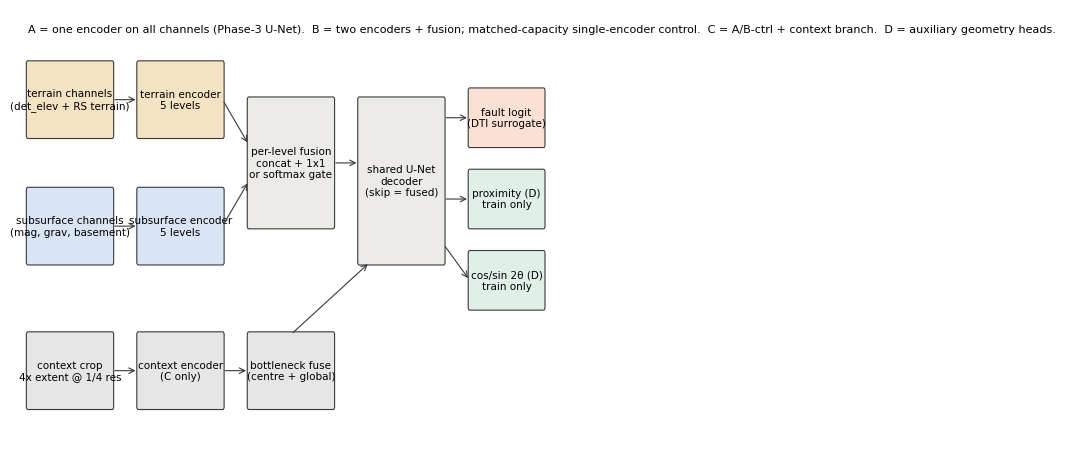

torch 2.14.1+cu126 | cuda True
NVIDIA GeForce RTX 3070 Laptop GPU: free 6.9 / 8.0 GiB
[p4_P4_B_ctrl_p256_s2026] device=cuda | stack on cuda:0 | amp=torch.bfloat16 | params=8,771,219
[p4_P4_B_ctrl_p256_s2026 f0] ep   1 loss 1.0005 inner 0.1588  (44s train, 8s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   2 loss 0.9487 inner 0.1426  (28s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   3 loss 0.8978 inner 0.1512  (28s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   4 loss 0.8279 inner 0.1381  (29s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   5 loss 0.6890 inner 0.1485  (29s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   6 loss 0.4344 inner 0.1346  (29s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f0] ep   7 loss 0.2483 inner 0.1301  (29s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f1] ep   1 loss 0.9911 inner 0.1768  (29s train, 7s eval)
[p4_P4_B_ctrl_p256_s2026 f1] ep   2 loss 0.9363 inner 0.1887  (29s train, 0s eval)
[p4_P4_B_ctrl_p256_s2026 f1] ep   3 loss 0.8932 inner 0.2071  (29s trai

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_P4_B_ctrl_p256_s2026] cross-fitted area DTI=0.1145  raw=0.0615
[p4_P4_B_concat_p256_s2026] device=cuda | stack on cuda:0 | amp=torch.bfloat16 | params=8,884,857
[p4_P4_B_concat_p256_s2026 f0] ep   1 loss 0.9661 inner 0.1289  (39s train, 7s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   2 loss 0.8943 inner 0.1355  (22s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   3 loss 0.8237 inner 0.1360  (22s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   4 loss 0.7084 inner 0.1471  (24s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   5 loss 0.4994 inner 0.1268  (25s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   6 loss 0.2892 inner 0.1908  (24s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   7 loss 0.1753 inner 0.1510  (24s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   8 loss 0.1306 inner 0.1257  (24s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep   9 loss 0.1050 inner 0.1532  (25s train, 0s eval)
[p4_P4_B_concat_p256_s2026 f0] ep  10 loss 0.0905 inner 0.1560  (25s t

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_P4_B_concat_p256_s2026] cross-fitted area DTI=0.1461  raw=0.0928
[p4_P4_B_gated_p256_s2026] device=cuda | stack on cuda:0 | amp=torch.bfloat16 | params=8,889,827
[p4_P4_B_gated_p256_s2026 f0] ep   1 loss 0.9674 inner 0.1723  (34s train, 5s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   2 loss 0.8961 inner 0.1463  (28s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   3 loss 0.8227 inner 0.1521  (30s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   4 loss 0.7128 inner 0.1736  (31s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   5 loss 0.5093 inner 0.1615  (33s train, 1s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   6 loss 0.2813 inner 0.1846  (33s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   7 loss 0.1712 inner 0.1614  (31s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   8 loss 0.1297 inner 0.1816  (34s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep   9 loss 0.1060 inner 0.1665  (31s train, 0s eval)
[p4_P4_B_gated_p256_s2026 f0] ep  10 loss 0.0885 inner 0.1957  (32s train, 0s 

C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()
C:\Use

[p4_P4_B_gated_p256_s2026] cross-fitted area DTI=0.1584  raw=0.0973


In [15]:
GROUPS = {g: tr.available_channels(ctx, names) for g, names in C4['channel_groups'].items()}
print({g: len(v) for g, v in GROUPS.items()})
ARCH, ARCH_TABLE = tr.resolve_arch_specs(C4, GROUPS, CFG.seed,
                                         channels_override={'P4_A_repro': tr.phase3_cnn_spec(ctx, 'CNN_A_dti').channels})
save(ARCH_TABLE, 'architecture_parameters', 'Phase-4 architectures: widths, channels, parameter counts')
display(ARCH_TABLE)
show(ev.fig_architecture(), 'encoder_architecture_diagram', 'A single / B dual + fusion / C context branch / D auxiliary heads')


def run_arch(name, section):
    spec = ARCH[name]
    exp = tr.cnn_exp_id(ctx, name, spec.patch_px)
    run = tr.run_cnn4_cv(ctx, exp, spec, overwrite=OVERWRITE)
    keys = ('arch', 'enc_width', 'dec_width', 'fusion', 'context', 'context_strict', 'aux_dist', 'aux_orient', 'loss', 'pretrained')
    manifest_row(exp, section, 'cnn4_cv', {k: getattr(spec, k) for k in keys}, spec.channels, run.dir)
    add_map(name, exp)
    return run


if RUN_DUAL_ENCODER:
    require_cuda()
    for name in ('P4_A_repro', 'P4_B_ctrl', 'P4_B_concat', 'P4_B_gated'):
        if name in ARCH:
            run_arch(name, '6')

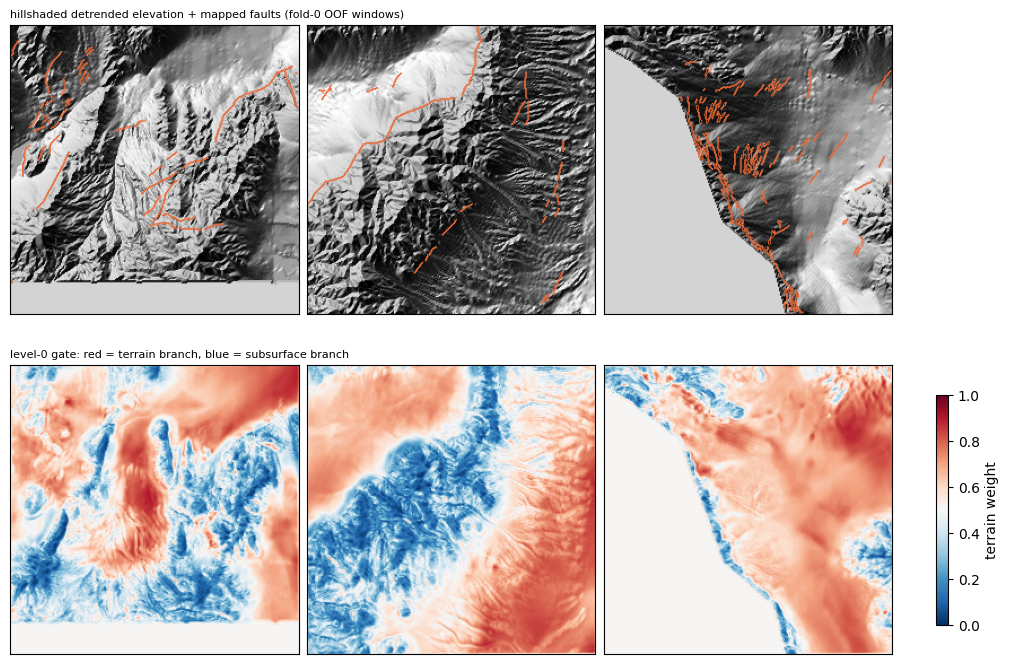

In [16]:
GEXP = tr.cnn_exp_id(ctx, 'P4_B_gated', 256)
if has_exp(GEXP):
    dev = tr.device_of()
    spec0, m0 = tr.load_cnn4_fold_models(ctx.paths.experiments / GEXP, dev)[0]
    gst = tr.to_tensor_stack(tr.cnn3.prepare_stack(spec0, ctx)[0], dev)
    lpt = ev.label_pixel_table(ctx)
    cent = lpt[lpt.fold == 0].groupby('seg_id')[['r', 'c']].median().sample(3, random_state=CFG.seed).to_numpy()
    elev = ctx.data.read_band('det_elev')
    H, W = ctx.data.shape
    fig, axs = plt.subplots(2, 3, figsize=(10, 6.8), constrained_layout=True)
    for j, (r, c) in enumerate(cent):
        r0, c0 = int(np.clip(r - 128, 0, H - 256)), int(np.clip(c - 128, 0, W - 256))
        g = tr.gate_window(m0, gst, r0, c0, spec0, dev)
        sl = (slice(r0, r0 + 256), slice(c0, c0 + 256))
        axs[0, j].imshow(_hillshade(np.nan_to_num(elev[sl])), cmap='gray')
        axs[0, j].contour(ctx.data.labels[sl].astype(float), levels=[0.5], colors='#eb6834', linewidths=0.6)
        im = axs[1, j].imshow(g, cmap='RdBu_r', vmin=0, vmax=1)
        for ax in axs[:, j]:
            ax.set_xticks([]), ax.set_yticks([])
    axs[0, 0].set_title('hillshaded detrended elevation + mapped faults (fold-0 OOF windows)', fontsize=8, loc='left')
    axs[1, 0].set_title('level-0 gate: red = terrain branch, blue = subsurface branch', fontsize=8, loc='left')
    fig.colorbar(im, ax=axs[1, :], shrink=0.7, label='terrain weight')
    show(fig, 'terrain_subsurface_evidence_maps', 'gated dual encoder: terrain vs subsurface reliance (fold-0 model, its validation windows)')
    del gst

## 7 · Multi-scale context and auxiliary geometry heads (`RUN_CONTEXT`, `RUN_AUX_HEADS`, `RUN_P4_DISCOVERY`)

* **C** = `P4_B_ctrl` + one mechanism: a low-resolution (1/4) context branch seeing 4× the patch extent (51 km). With `context_strict` its training context zeroes everything outside the fold's training zone. Question: better long-fault continuity (`recall_w_len_>10`) without losing short-fault localisation (`recall_w_len_<1`, `short_recall_w`).
* **D** = `P4_B_ctrl` + training-only heads: proximity (≤ 2 km) and strike as (cos 2θ, sin 2θ), supervised only where the visible-label structure tensor is coherent (no supervision at intersections). Output is still one fault raster.

In [17]:
if RUN_CONTEXT:
    require_cuda()
    run_arch('P4_C_context', '7')
if RUN_AUX_HEADS:
    require_cuda()
    run_arch('P4_D_aux', '7')
for name in ARCH:
    if name not in MAPS and has_exp(tr.cnn_exp_id(ctx, name, 256)):
        add_map(name, tr.cnn_exp_id(ctx, name, 256))
if RUN_P4_DISCOVERY:
    require_cuda()
    for name in C4['architectures']['discovery']:
        if name in MAPS:
            ep = tr.run_cnn4_discovery_all(ctx, name, ARCH[name], tr.cnn_exp_id(ctx, name, 256), overwrite=OVERWRITE)
            manifest_row(f'disc_{name}', '7', 'cnn4_discovery', {'epochs': ep}, ARCH[name].channels, ctx.paths.experiments)
DISC += [n for n in ARCH if n not in DISC and ctx.has_discovery(n)]
CMP_ARCH = pd.DataFrame()
ARCH_KEYS = [k for k in ['G1', 'CNN_A_dti', *ARCH] if k in MAPS]
if any(k in MAPS for k in ARCH):
    SC_ARCH = ev.scorecard(ctx, {k: MAPS[k] for k in ARCH_KEYS}, [k for k in DISC if k in ARCH_KEYS], MATCH_FRAC)
    CMP_ARCH = ev.comparison_rows(SC_ARCH['score'], [('P4_A_repro', 'CNN_A_dti'), ('P4_B_ctrl', 'CNN_A_dti'),
                                                     ('P4_B_concat', 'P4_B_ctrl'), ('P4_B_gated', 'P4_B_ctrl'),
                                                     ('P4_B_gated', 'P4_B_concat'), ('P4_C_context', 'P4_B_ctrl'),
                                                     ('P4_D_aux', 'P4_B_ctrl')], 'architectures')
    DUAL = SC_ARCH['score'].merge(ARCH_TABLE, on='model', how='left')
    save(DUAL, 'dual_encoder_results', 'P4 architectures: scorecard + parameter counts', headline=True)
    save(CMP_ARCH, 'architecture_deltas', 'architecture candidate - control deltas (matched-capacity control for B)')
    display(CMP_ARCH.round(4))
    show(ev.fig_training_curves({k: run_history(k) for k in ARCH if k in MAPS}), 'p4_training_curves',
         'P4 train loss and inner-val binary-area DTI per fold')

torch 2.14.1+cu126 | cuda True
NVIDIA GeForce RTX 3070 Laptop GPU: free 5.6 / 8.0 GiB
[p4_P4_C_context_p256_s2026] device=cuda | stack on cuda:0 | amp=torch.bfloat16 | params=9,584,931
[p4_P4_C_context_p256_s2026 f0] ep   1 loss 0.9826 inner 0.1521  (47s train, 4s eval)
[p4_P4_C_context_p256_s2026 f0] ep   2 loss 0.9212 inner 0.1646  (33s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   3 loss 0.8604 inner 0.1853  (36s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   4 loss 0.7632 inner 0.1680  (38s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   5 loss 0.5698 inner 0.1357  (37s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   6 loss 0.3210 inner 0.1750  (39s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   7 loss 0.2034 inner 0.1615  (37s train, 0s eval)
[p4_P4_C_context_p256_s2026 f0] ep   8 loss 0.1442 inner 0.1536  (38s train, 1s eval)
[p4_P4_C_context_p256_s2026 f0] ep   9 loss 0.1253 inner 0.1691  (38s train, 0s eval)
[p4_P4_C_context_p256_s2026 f1] ep   1 lo

MemoryError: Unable to allocate 3.60 MiB for an array with shape (471946,) and data type float64

## 8 · Masked geophysical pretraining (P2: `RUN_SSL_PRETRAIN`, `RUN_SSL02`)

Encoder = the `ssl.arch` model's encoder (same class, width, channels). **strict**: one pretraining per fold on `folds.train(k)` (validation and buffer features never seen); **transductive**: one on the whole footprint (legitimate for the leaderboard, optimistic locally). The two are never mixed in one row. Reconstruction quality is diagnostic only.

In [ ]:
S = C4['ssl']
SSL_BASE = ARCH.get(S['arch'])
SSL_FLAGS = {'SSL01': RUN_SSL_PRETRAIN, 'SSL02': RUN_SSL02}
if any(SSL_FLAGS.values()):
    if SSL_BASE is None:
        raise RuntimeError('ssl.arch is not an enabled architecture in section 6: ' + S['arch'])
    require_cuda()
    for key, flag in SSL_FLAGS.items():
        if not flag:
            continue
        sp = ssl.ssl_spec_for(SSL_BASE, key, S[key], CFG.seed)
        for proto in S[key]['protocols']:
            for r in ssl.run_protocol(ctx, key, sp, proto, overwrite=OVERWRITE):
                manifest_row(r.exp_id, '8', 'ssl_pretrain', {'mask_mode': sp.mask_mode, 'protocol': proto, 'epochs': sp.epochs},
                             sp.channels, r.dir)
SSL_IDS = sorted(p.name for p in ctx.paths.experiments.glob('ssl_*') if (p / 'history.csv').exists())
SSLH = ssl.history_table(ctx, SSL_IDS)
if len(SSLH):
    save(SSLH, 'ssl_pretraining_history', 'SSL pretraining curves: train / held-out patch loss, masked R2 per modality', headline=True)
    show(ssl.fig_ssl_history(SSLH), 'ssl_pretraining_curves', 'reconstruction is diagnostic only, never a promotion argument')

## 9 · Fine-tuning and evaluation (`RUN_SSL_FINETUNE`)

Fine-tuned model = `ssl.arch` spec with `pretrained` set (strict: encoder of the same fold). The random-init control is that architecture's own §6 run: same channels, splits, budgets, seed. Pseudo-discovery for SSL uses the transductive encoder (discovery models already see the withheld systems as inputs).

In [ ]:
FT_NAMES = []
for key in ('SSL01', 'SSL02'):
    for proto in S[key]['protocols']:
        tmpl = ssl.encoder_path_template(ctx, key, proto)
        name = f'{key}_{proto}'
        ready = all(Path(tmpl.format(fold=k)).exists() for k in ctx.fold_ids)
        if RUN_SSL_FINETUNE and ready and SSL_BASE is not None:
            require_cuda()
            spec = replace(SSL_BASE, name=name, pretrained=tmpl, **S['finetune'])
            run_ft = tr.run_cnn4_cv(ctx, tr.cnn_exp_id(ctx, name, spec.patch_px), spec, overwrite=OVERWRITE)
            manifest_row(run_ft.exp_id, '9', 'ssl_finetune', {'protocol': proto, 'pretrained': tmpl, **S['finetune']},
                         spec.channels, run_ft.dir)
        if has_exp(tr.cnn_exp_id(ctx, name, 256)):
            add_map(name, tr.cnn_exp_id(ctx, name, 256))
            FT_NAMES.append(name)
if RUN_P4_DISCOVERY and 'SSL01_transductive' in MAPS and SSL_BASE is not None:
    spec = replace(SSL_BASE, name='SSL01_transductive', pretrained='', **S['finetune'])
    ep = tr.run_cnn4_discovery_all(ctx, 'SSL01_transductive', spec, tr.cnn_exp_id(ctx, 'SSL01_transductive', 256),
                                   overwrite=OVERWRITE, pretrained_path=ssl.encoder_path_template(ctx, 'SSL01', 'transductive'))
    manifest_row('disc_SSL01_transductive', '9', 'cnn4_discovery', {'epochs': ep}, spec.channels, ctx.paths.experiments)
DISC += [n for n in FT_NAMES if n not in DISC and ctx.has_discovery(n)]
CMP_SSL = pd.DataFrame()
if FT_NAMES and S['arch'] in MAPS:
    keys = [S['arch'], *FT_NAMES]
    SC_SSL = ev.scorecard(ctx, {k: MAPS[k] for k in keys}, [k for k in DISC if k in keys], MATCH_FRAC)
    CMP_SSL = ev.comparison_rows(SC_SSL['score'], [(n, S['arch']) for n in FT_NAMES], 'ssl_finetune')
    CMP_SSL['protocol'] = ['strict' if 'strict' in c else 'transductive' for c in CMP_SSL.candidate]
    save(SC_SSL['score'].merge(CMP_SSL[['candidate', 'protocol']], left_on='model', right_on='candidate', how='left'),
         'ssl_finetuning_results', 'SSL fine-tuning vs random-init control; strict and transductive reported separately', headline=True)
    display(CMP_SSL.round(4))

## 10 · Optional high-resolution DEM / EO interfaces (`RUN_EXTERNAL_DEM`, `RUN_EO_FOUNDATION`)

No download happens here. EO01 proposes a handful of target windows (strong mapped faults, short missed faults, weak-terrain faults, candidate lineaments, one per region); download the matching GEMS-provided 1 m DEM tiles to `data/external/dem1m/` and re-run: 1 m statistics are aggregated to the 100 m grid (max, p90, std, steep fraction) and evaluated inside the AOIs only. EO02 (Sentinel-2) and EO03 (foundation embeddings) are interfaces in `gems_bench/external_eo.py`; EO03 refuses geophysical bands and is deferred.

In [ ]:
print('Eligibility checklist before any external data or weights:')
for item in eo.ELIGIBILITY_CHECKLIST:
    print(' -', item)
AOI = None
if RUN_EXTERNAL_DEM:
    _, K_ref = ev.recovery_table(ctx, {'G1': MAPS['G1']}, MATCH_FRAC)
    cand_p = ctx.p3paths.datasets / 'candidate_lineaments_600m.parquet'
    AOI = eo.select_aois(ctx, K_ref, 'G1', pd.read_parquet(cand_p) if cand_p.exists() else None)
    save(AOI, 'eo01_aoi_candidates', 'EO01 target windows for 1 m DEM downloads (fill dem_file after download)')
    display(AOI)
    dem_dir = ctx.paths.root / 'data' / 'external' / 'dem1m'
    tiles = sorted(dem_dir.glob('*.tif')) if dem_dir.exists() else []
    print('local 1 m DEM tiles:', len(tiles))
    for f in tiles:
        ctx.save_raster(eo.dem1m_features(f, ctx), f'dem1m_{f.stem}', '1 m DEM statistics on the 100 m grid (NaN outside coverage)')
if RUN_EO_FOUNDATION:
    print('EO03 is deferred (P3): FoundationEmbeddingExtractor rejects geophysical bands and never downloads weights.')

## 11 · Model complementarity and geological error atlas

All at the matched budget (`match_frac`, per-fold top masks): OOF rank correlation, mask Jaccard, unique recovered km, weighted recall on faults missed by G1 and by CNN_A_dti, disagreement > 1 km from labels, far (false-positive-like) area, mask elongation (lineament coherence), recall by length / curvature / endpoints / intersections, unique withheld systems. Figures compare the best new model against G1 and CNN_A_dti.

In [ ]:
NEW = [k for k in MAPS if k not in ('G1', 'G3', 'G3_D2', 'CNN_A_bcedice', 'CNN_A_dti', 'CNN_B_bcedice') and '_drop_' not in k]
COMP_KEYS = [k for k in ['G1', 'G3_D2', 'CNN_A_dti', *NEW] if k in MAPS]
SC_ALL, UNI = None, None
if len(COMP_KEYS) >= 2:
    SC_ALL = ev.scorecard(ctx, {k: MAPS[k] for k in COMP_KEYS}, [k for k in DISC if k in COMP_KEYS], MATCH_FRAC)
    save(SC_ALL['recovery'], 'fault_recovery_by_length', 'recall at the matched budget by length / curvature / structure / archetype',
         headline=True)
    PAIR, PER = ev.complementarity(ctx, {k: MAPS[k] for k in COMP_KEYS}, MATCH_FRAC, refs=('G1', 'CNN_A_dti'),
                                   support=SC_ALL['support'])
    save(pd.concat([PAIR.assign(kind='pair'), PER.assign(kind='model')], ignore_index=True), 'model_complementarity',
         'pairwise correlation / overlap / unique km + per-model recall on faults missed by G1 and CNN_A_dti', headline=True)
    UNI, UNI_LIST = ev.unique_discovery_systems(ctx, SC_ALL['disc_objs'], [k for k in COMP_KEYS if k in DISC],
                                                refs=('G1', 'G3_D2', 'CNN_A_dti'), frac=MATCH_FRAC)
    save(UNI, 'unique_discovery_systems', 'withheld systems recovered by a model and missed by a reference (excl policy)')
    if len(UNI_LIST):
        save(UNI_LIST, 'unique_discovery_systems_list', 'per-system list of unique recoveries')
    display(PER.round(3))
    display(UNI)

In [ ]:
if SC_ALL is not None and NEW:
    s = SC_ALL['score'].set_index('model')
    BEST_NEW = s.loc[[k for k in NEW if k in s.index]].geo_dti.idxmax()
    print('best new model by geographic DTI:', BEST_NEW)
    for ref in ('G1', 'CNN_A_dti'):
        if ref in MAPS:
            show(ev.fig_disagreement(ctx, MAPS, BEST_NEW, ref, MATCH_FRAC), f'disagreement_{BEST_NEW}_vs_{ref}',
                 'top-mask disagreement at the matched budget')
            win = ev.atlas_windows(ctx, SC_ALL['support'], BEST_NEW, ref, n=4)
            save(win, f'error_atlas_windows_{BEST_NEW}_vs_{ref}', 'atlas windows: recovered by one model only / missed by both')
            show(ev.fig_error_atlas(ctx, MAPS, BEST_NEW, ref, MATCH_FRAC, win), f'error_atlas_{BEST_NEW}_vs_{ref}',
                 'recovered / missed fault atlas')
    cdf, _, cpaths = lineaments.extract_candidates(ctx, MAPS[BEST_NEW], top_frac=MATCH_FRAC, model=BEST_NEW)
    if len(cdf):
        lineaments.write_lineaments(ctx, cdf, cpaths, ctx.paths.datasets / f'candidate_lineaments_{BEST_NEW}.gpkg')
        show(lineaments.atlas_figure(ctx, cdf, cpaths, MAPS[BEST_NEW], n=12), f'candidate_lineament_gallery_{BEST_NEW}',
             'ranked new-candidate lineaments from OOF probabilities (interpretation, not the submission)')

## 12 · Results comparison and next decisions

Promotion (section 12 of the brief, thresholds in `experiments.yaml: promotion`): better geographic DTI (≥ 0.005, ≥ 2/3 folds, worst fold not lower), better pseudo-discovery (excl gain ≥ 0.005, retained_fp not lower, area ≤ 1.5× control), better < 2 km recall (≥ 0.02), ≥ 2 unique withheld systems, or a validated ensemble gain. Expensive models (dual, context, aux, SSL) need two criteria. Attractive maps and training loss are never criteria.

In [ ]:
RULES = C4['promotion']
PAIRS = [('RS02_G1_terrain', 'RS01_G1'), ('RS03_G3_potential', 'G3_D2'), ('RS04_G3_crossmodal', 'G3_D2'),
         ('RS05_G3_noSS_RS', 'RS05c_G3_noSS'), ('DL00_CNN_B_dti', 'CNN_B_bcedice'), ('DL02_CNN_TMGB_dti', 'CNN_A_dti'),
         ('P4_B_concat', 'P4_B_ctrl'), ('P4_B_gated', 'P4_B_ctrl'), ('P4_C_context', 'P4_B_ctrl'), ('P4_D_aux', 'P4_B_ctrl'),
         ('SSL01_strict', S['arch']), ('SSL01_transductive', S['arch']), ('SSL02_strict', S['arch'])]
PROMO = pd.DataFrame()
if SC_ALL is not None:
    ALL_KEYS = sorted(set(COMP_KEYS) | {x for pr in PAIRS for x in pr if pr[0] in MAPS and pr[1] in MAPS})
    SC_FULL = ev.scorecard(ctx, {k: MAPS[k] for k in ALL_KEYS}, [k for k in DISC if k in ALL_KEYS], MATCH_FRAC)
    sc = SC_FULL['score']
    save(sc, 'phase4_model_comparison', 'every Phase-4 model + references: geographic / discovery / thin-structure columns', headline=True)
    save(sc[~sc.model.str.startswith(('G', 'RS'))], 'cnn_architecture_comparison', 'CNN controls, P4 architectures, SSL fine-tunes',
         headline=True)
    save(SC_FULL['disc_summary'], 'pseudo_discovery_results', 'pseudo-discovery: matched budgets + cross-fitted area per policy',
         headline=True)
    PROMO = pd.DataFrame([ev.promotion(sc, a, b, RULES, UNI) for a, b in PAIRS if a in MAPS and b in MAPS])
    save(PROMO, 'phase4_promotion', 'section-12 promotion decisions (candidate vs its control)', headline=True)
    display(PROMO)
    show(ev.fig_metric_bars(sc, 'geo_dti', 'Geographic cross-fitted area DTI (dots = folds)',
                            [c for c in sc if c.startswith('dti_fold')], 'G1'), 'geo_dti_comparison', 'all Phase-4 models vs references')
    for pol in ('excl', 'retained_fp'):
        col = f'disc_dti_{pol}'
        if col in sc and sc[col].notna().sum() > 1:
            show(ev.fig_metric_bars(sc, col, f'Pseudo-discovery DTI, policy {pol} (cross-fitted area, 3 splits)'),
                 f'pseudo_discovery_comparison_{pol}', 'pseudo-discovery: compare within one policy only')

In [ ]:
ENS = None
if RUN_PHASE4_ENSEMBLE and len(PROMO):
    members = [m for m in ['G1', 'CNN_A_dti', *PROMO[PROMO.promote].candidate] if m in MAPS]
    if len(members) >= 2:
        ENS, ENS_PER = ensemble3.nested_ensemble_eval(ctx, {m: MAPS[m] for m in members})
        save(ENS, 'phase4_ensemble_validation', 'nested ensemble: every weight / budget chosen on the other folds')
        dsum = None
        if all(ctx.has_discovery(m) for m in members):
            preds = ensemble3.discovery_ensemble_preds(ctx, members)
            dc, _ = discovery3.discovery_curves(ctx, members + ['ens'], policies=('excl', 'retained_fp'), variants=('model',),
                                                extra_preds=preds)
            dsum = discovery3.discovery_summary(dc)
            save(dsum, 'phase4_ensemble_discovery', 'rank-mean ensemble vs members on pseudo-discovery')
        for method in ['rank_mean'] + [m for m in ENS.method if m.startswith('weighted_rank')]:
            print(ensemble3.promotion_decision(ENS, dsum, method))
        display(ENS.round(4))

In [ ]:
g = globals().get
BLOCKS = [
    ('Reused Phase-3 runs (not retrained)', P3_REG[['exp_id', 'dti_crossfit_area', 'area_fold_min']], ''),
    ('RQ1-RQ2 — RS features in LightGBM', g('ABL'),
     'a feature family is adopted only through a section-12 criterion vs its control (phase4_promotion.csv); gain share is descriptive.'),
    ('RS redundancy audit (top 15)', RED.sort_values('max_abs_spearman', ascending=False).head(15) if len(RED) else None,
     'RS features with |rho| >= 0.95 vs an existing feature are excluded from the RS groups.'),
    ('RQ3 — DL00 / DL01 / DL02 CNN controls', g('CMP_CNN'),
     'DL01 compares CNN_A_dti and CNN_A_bcedice on identical splits, policies and budgets; excl and retained_fp are read separately.'),
    ('DL01 pseudo-discovery (cross-fitted area)', g('D01'), ''),
    ('RQ4 — dual encoder, context, auxiliary heads', g('CMP_ARCH'),
     'B is credited only against the parameter-matched single encoder P4_B_ctrl; expensive models need 2 criteria.'),
    ('RQ5 — SSL fine-tuning', g('CMP_SSL'), 'strict = validation features excluded from pretraining; transductive is optimistic locally.'),
    ('RQ6 — external EO', g('AOI') if g('AOI') is not None else 'interfaces only; no external data evaluated yet.',
     'external sources pass the eligibility checklist first.'),
    ('RQ7 — complementarity (per model)', g('PER'), 'a model joins an ensemble only through the nested ensemble rule.'),
    ('Unique withheld systems', g('UNI'), ''),
    ('Promotion decisions', PROMO, 'configs/phase4/experiments.yaml: promotion'),
    ('Nested ensemble', g('ENS'), 'promoted only if it beats the nested best single in >= 2 folds and holds on pseudo-discovery.'),
]
ev.write_findings(OUT / 'PHASE4_FINDINGS.md', BLOCKS)
ctx.manifest.add('PHASE4_FINDINGS', OUT / 'PHASE4_FINDINGS.md', 'report', 'Phase-4 findings with decision rules')
print((OUT / 'PHASE4_FINDINGS.md').read_text(encoding='utf-8')[:4000])